In [4]:
import os
import torch
import random
import matplotlib.pyplot as plt
F = torch.nn.functional
torch.set_num_threads(1)

In [5]:
with open("names.txt", "r+") as file:
    contents = file.read()

split_lines = contents.splitlines()
random.shuffle(split_lines)
char_set = sorted(set(''.join(split_lines)))

In [109]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 10), requires_grad=True, generator=g)
W1 = torch.randn((30, 200), generator=g) * 0.1
B1 = torch.randn((200,), generator=g) * 0.5
W2 = torch.randn((200, 27), generator=g) * 0.01
B2 = torch.randn((27,), generator=g) * 0
block_size = 3
parameters = list([C, W1, B1, W2, B2])

ch2i = {}
i2ch = {}
ch2i['.'] = 0
i2ch[0] = '.'
for i, v in enumerate(char_set):
    ch2i[v] = i + 1
    i2ch[i + 1] = v
print(W2.is_leaf, B2.is_leaf)
for p in parameters:
    p.requires_grad = True

True True


In [105]:
def convert(names):
    X = []
    Y = []
    for name in names:
        context = ['.'] * block_size
        name_chars = list(name)
        for ch in name_chars:
            nums = []
            for c in context:
                nums.append(ch2i[c])
            X.append(nums)
            Y.append(ch2i[ch])
            context = context[1:] + [ch]
    tx = torch.tensor(X)
    ty = torch.tensor(Y)
    return tx, ty

In [128]:
train_set_size = int(0.8 * len(split_lines))
dev_set_size = int(0.1 * len(split_lines)) + train_set_size
test_set_size = dev_set_size + int(0.1 * len(split_lines))

train_set = split_lines[0:train_set_size]
dev_set = split_lines[train_set_size:dev_set_size]
test_set = split_lines[dev_set_size:test_set_size]

Xtr, Ytr = convert(train_set)
Xdev, Ydev = convert(dev_set)
Xtest, Ytest = convert(test_set)

In [133]:
for _ in range(300000):
    batch = torch.randint(0, len(Xtr), (32,))
    batch_x = Xtr[batch]
    batch_y = Ytr[batch]
    dim = C[batch_x].view(-1, 30)

    preact = dim @ W1 + B1
    hidden = torch.tanh(preact)
    logits = hidden @ W2 + B2
    loss = F.cross_entropy(logits, batch_y)
    for p in parameters:
        p.grad = None
    loss.backward()
    with torch.no_grad():
        for p in parameters:
            p.data -= 0.1 * p.grad

print(loss)

tensor(1.8663, grad_fn=<NllLossBackward0>)


In [136]:
with torch.no_grad():
    dim = C[Xdev].view(-1, 30)
    preact = dim @ W1 + B1
    hidden = torch.tanh(preact)
    logits = hidden @ W2 + B2
    loss = F.cross_entropy(logits, Ydev)
    print(loss)

tensor(2.2423)


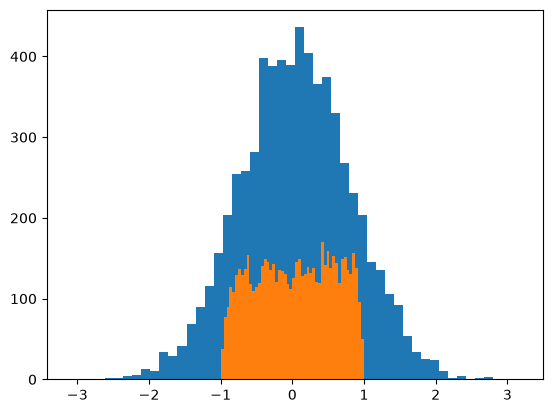

In [120]:
import matplotlib.pyplot as plt
plt.hist(preact.view(-1).tolist(), 50);
plt.hist(hidden.view(-1).tolist(), 50);

In [117]:
print(W1.std())
print(B1.std())
print(preact[:, 0])

tensor(0.1021, grad_fn=<StdBackward0>)
tensor(0.5117, grad_fn=<StdBackward0>)
tensor([-1.6494, -0.7122, -0.5610, -1.1600, -0.9367, -0.9805, -1.0236, -1.8163,
        -1.8163, -0.7455, -1.8478, -1.0110, -0.6534, -0.4764, -1.5932, -0.7504,
        -2.0924, -1.8163, -0.4778, -1.5421, -1.8163, -2.5149, -1.4475, -0.8904,
        -0.9830, -0.6534, -1.4905, -1.5318, -0.4082, -1.8163, -1.2232, -0.5332],
       grad_fn=<SelectBackward0>)


In [118]:
print(batch_x[:5])
print(C.std())
print(C[:3])
print(dim[:3, :6])
print(B1[0])


tensor([[ 8, 15, 12],
        [ 2, 18,  1],
        [ 8,  1,  5],
        [ 0, 12,  1],
        [ 0,  0, 10]])
tensor(1.0007, grad_fn=<StdBackward0>)
tensor([[ 1.5674, -0.2373, -0.0274, -1.1008,  0.2859, -0.0296, -1.5471,  0.6049,
          0.0791,  0.9046],
        [-0.4713,  0.7868, -0.3284, -0.4330,  1.3729,  2.9334,  1.5618, -1.6261,
          0.6772, -0.8404],
        [ 0.9849, -0.1484, -1.4795,  0.4483, -0.0707,  2.4968,  2.4448, -0.6701,
         -1.2199,  0.3031]], grad_fn=<SliceBackward0>)
tensor([[-1.1641,  1.2473, -0.2706, -1.3635,  1.3066,  0.3231],
        [ 0.9849, -0.1484, -1.4795,  0.4483, -0.0707,  2.4968],
        [-1.1641,  1.2473, -0.2706, -1.3635,  1.3066,  0.3231]],
       grad_fn=<SliceBackward0>)
tensor(-1.0352, grad_fn=<SelectBackward0>)


In [119]:
print(Xtr[:8])
print(Ytr[:8])
print(batch[:8])
print((Xtr != 0).sum())

tensor([[ 0,  0,  0],
        [ 0,  0, 11],
        [ 0, 11,  1],
        [11,  1,  3],
        [ 1,  3,  5],
        [ 3,  5, 25],
        [ 0,  0,  0],
        [ 0,  0,  2]])
tensor([11,  1,  3,  5, 25, 14,  2, 18])
tensor([ 38591, 139766, 145976,  37071, 133125,  62945,  91293,  97030])
tensor(316996)
